In [1]:
import pandas as pd
import re
from datetime import datetime
import numpy as np
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text
import os

In [2]:
# Got GISAID data from Louise

In [3]:
#LATESTGIS = "./metadata/sequence_metadata/gisaid_metadata_dwnld-2025-01-09.tsv"
LATESTGIS = "./metadata/sequence_metadata/gisaid_metadata_dwnld-2025-05-28.tsv"

In [4]:
data_gisaid = pd.read_csv(LATESTGIS, sep = "\t")

In [7]:
print(len(data_gisaid))

# September 18, 2024 pull - 45,005 sequences
# January 9, 2025 pull - 36,344 sequences?
# May 28, 2025 pull - 43,230 seqs

43230


In [8]:
# Function 1: making Collection Date a datetime object
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [9]:
# Function 2: Detemining duplicate strains
def to_dedupe(df):
    strain_count = df["strain"].value_counts()
    strain_count = strain_count.rename_axis("strain").reset_index()
    duplicate_strains = []
    for strain, count in strain_count.iterrows():
        if count['count'] > 1:
            duplicate_strains.append(count['strain'])
    duplicates = pd.DataFrame(duplicate_strains)
    return(duplicates)

In [10]:
# Step 1: Clean and organize metadata

In [11]:
# Filter for region = North America and host = Avian

data_gisaid_filtered = data_gisaid[(data_gisaid["region"] == "North America") & (data_gisaid["host"] == "Avian")]

In [13]:
# Check work

print(data_gisaid_filtered["region"].value_counts())
print(data_gisaid_filtered["host"].value_counts())
print(len(data_gisaid_filtered))

# September 18, 2024 pull - ~7000 sequences
# January 9, 2025 pull - 9991 sequences
# May 28, 2025 pull - 13681 seqs

region
North America    13681
Name: count, dtype: int64
host
Avian    13681
Name: count, dtype: int64
13681


In [14]:
# Filter for date = 2022, 2023, 2024

date_split = data_gisaid_filtered["date"].str.split(pat = "-", expand = True)
data_gisaid_filtered_copy = data_gisaid_filtered.copy()
data_gisaid_filtered_copy["year"] = date_split[0]

years_of_outbreak = ("2021", "2022", "2023", "2024")

data_gisaid_filtered_current = data_gisaid_filtered_copy[data_gisaid_filtered_copy["year"].isin(years_of_outbreak)]

In [15]:
# Check work

print(data_gisaid_filtered_current["year"].value_counts())

year
2022    6643
2023    1895
2024    1654
2021      46
Name: count, dtype: int64


In [20]:
# First, remove samples with just collection year (no month or day)

data_gisaid_filtered_current = data_gisaid_filtered_current[~data_gisaid_filtered_current["date"].str.match(r"^\d{4}-XX-XX$")]
print(len(data_gisaid_filtered_current))

# September 18, 2024 pull - 5640 sequences
# January 9, 2025 pull - 8199 sequences
# May 28, 2025 pull - 9567 seqs

9567


In [21]:
# Next, filter to samples only after November 1, 2021

data_gisaid_filtered_current_2 = data_gisaid_filtered_current[(data_gisaid_filtered_current["date"] >= '2021-11-01')]
print(len(data_gisaid_filtered_current_2))

# May 28, 2025 pull - 9533 seqs

9533


In [22]:
# Standardize strain name

gisaid_filtered_current_strain = data_gisaid_filtered_current_2.copy()

gisaid_filtered_current_strain["strain"] = gisaid_filtered_current_strain["strain"].str.lower().replace("-","").replace(" ","").replace("_","").replace("'","")

In [23]:
# Pull host and location from strain name

strain_split = gisaid_filtered_current_strain["strain"].str.split(pat = "/", expand = True)

gisaid_filtered_current_strain["State"] = strain_split[2]

gisaid_filtered_current_strain["strain_host"] = strain_split[1]

In [24]:
state_corrections_dict = {"al":"alabama",
                          "ak":"alaska",
                          "ab":"alberta",
                          "az":"arizona",
                          "ar":"arkansas",
                          "bc":"britishcolumbia",
                          "ca":"california",
                          "co":"colorado",
                          "ct":"connecticut",
                          "districtofcolumbia":"dc",
                          "de":"delaware",
                          "fl":"florida",
                          "ga":"georgia",
                          "hi":"hawaii",
                          "id":"idaho",
                          "il":"illinois",
                          "in":"indiana",
                          "ia":"iowa",
                          "ks":"kansas",
                          "ky":"kentucky",
                          "la":"louisiana",
                          "me":"maine",
                          "mb":"manitoba",
                          "md":"maryland",
                          "ma":"massachusetts",
                          "mi":"michigan",
                          "mn":"minnesota",
                          "ms":"mississippi",
                          "mo":"missouri",
                          "mt":"montana",
                          "ne":"nebraska",
                          "nv":"nevada",
                          "nb":"newbrunswick",
                          "nl":"newfoundland",
                          "nh":"newhampshire",
                          "nj":"newjersey",
                          "nm":"newmexico",
                          "ny":"newyork",
                          "nc":"northcarolina",
                          "nd":"northdakota",
                          "nt":"northwestterritories",
                          "ns":"novascotia",
                          "nu":"nunavut",
                          "oh":"ohio",
                          "ok":"oklahoma",
                          "on":"ontario",
                          "or":"oregon",
                          "pa":"pennsylvania",
                          "pe":"princeedwardisland",
                          "pei":"princeedwardisland",
                          "pr":"puertorico",
                          "qc":"quebec",
                          "ri":"rhodeisland",
                          "sk":"saskatchewan",
                          "sc":"southcarolina",
                          "sd":"southdakota",
                          "tn":"tennessee",
                          "tx":"texas",
                          "ut":"utah",
                          "vt":"vermont",
                          "va":"virginia",
                          "wa":"washington",
                          "wv":"westvirginia",
                          "wi":"wisconsin",
                          "wy":"wyoming",
                          "yt":"yukon",
                          "louisana":"louisiana",
                          "flordia":"florida",
                          "edomex":"mexicostate"
                         }

In [26]:
# Fix state names if necessary

print(set(gisaid_filtered_current_strain["State"]))

gisaid_updtstates = gisaid_filtered_current_strain.copy()

gisaid_updtstates["State"] = gisaid_filtered_current_strain["State"].map(state_corrections_dict).fillna(gisaid_updtstates["State"])

print(set(gisaid_updtstates["State"]))

{'washington', 'ab', 'nu', 'nb', 'nebraska', 'novascotia', 'alberta', 'saskatchewan', 'alabama', 'northdakota', 'oregon', 'newyork', 'newfoundland', 'me', 'on', 'virginia', 'missouri', 'rhodeisland', 'panama', 'colorado', 'alaska', 'pei', 'wisconsin', 'montana', 'southdakota', 'ontario', 'unknown', 'sk', 'qc', 'maine', 'queretaro', 'arkansas', 'georgia', 'ns', 'puebla', 'mexicostate', 'tennessee', 'delaware', 'texas', 'mississippi', 'puertorico', 'kentucky', 'quebec', 'florida', 'southcarolina', 'nevada', 'westvirginia', 'michigan', 'newhampshire', 'pe', 'pennsylvania', 'louisiana', 'morelos', 'illinois', 'newjersey', 'durango', 'nl', 'princeedwardisland', 'idaho', 'oklahoma', 'guanajuato', 'kansas', 'connecticut', 'nunavut', 'massachusetts', 'costarica', 'hawaii', 'mb', 'honduras', 'newmexico', 'jalisco', 'minnesota', 'britishcolumbia', 'california', 'indiana', 'bc', 'colima', 'arizona', 'guatemala', 'usa', 'vermont', 'iowa', 'utah', 'maryland', 'northcarolina', 'ohio', 'wyoming', 'ma

In [28]:
# Determine which hosts are present

gisaid_unique_avian_hosts = pd.DataFrame(set(gisaid_updtstates["strain_host"]))

print(len(gisaid_unique_avian_hosts)) 

#182 unique species
# January 9, 2025 pull - 216 unique species
# May 28, 2025 - 234 unique species

#DATE_UPDATED = "2025-01-27"
DATE_UPDATED = "2025-05-28"

gisaid_unique_avian_hosts.to_csv("./metadata/helpful_lists/gisaid_avian_hosts_updated_" + DATE_UPDATED + ".csv", sep = ',')

234


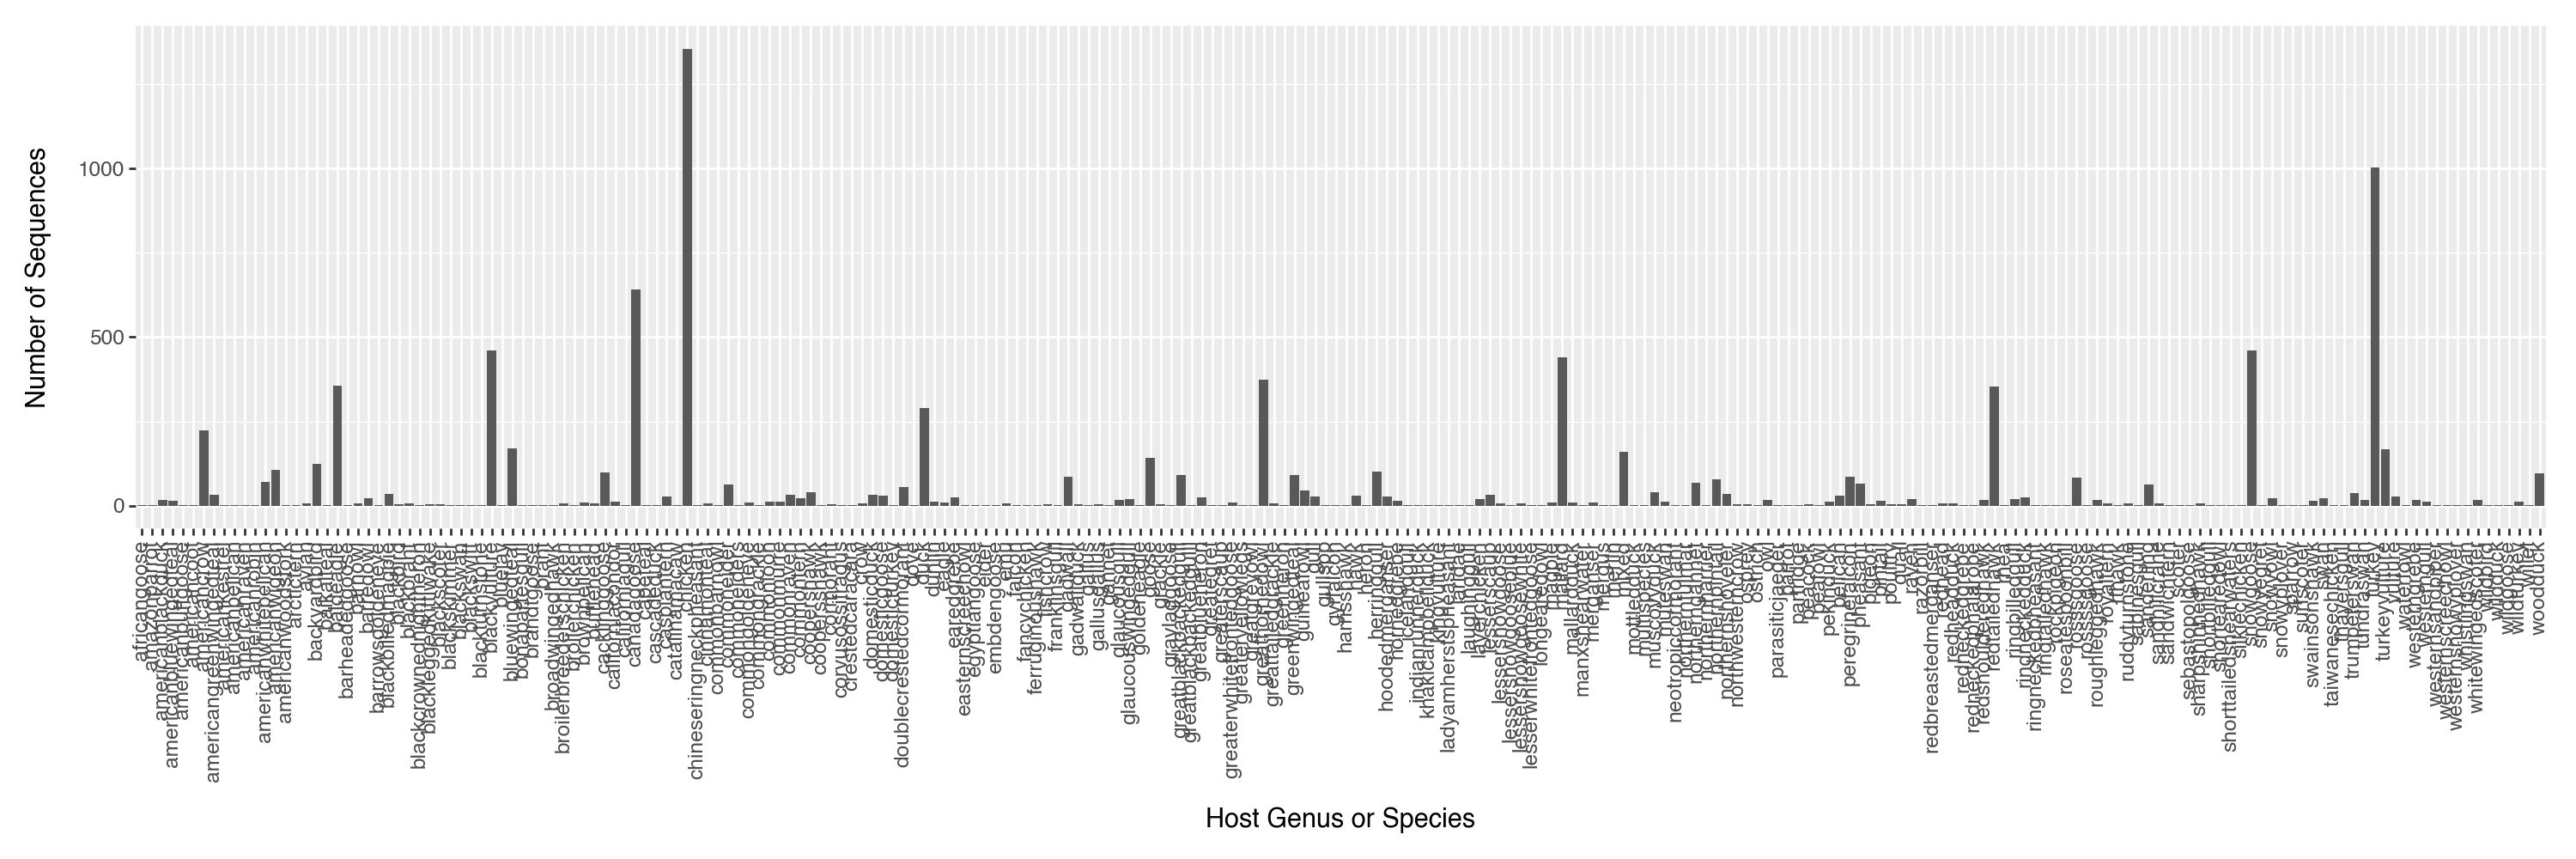

In [29]:
# Plot the hosts present in the GISAID data

gisaid_avian_hosts = pd.DataFrame(gisaid_updtstates["strain_host"])

# plot this using ggplot
(
    ggplot(gisaid_avian_hosts, aes(x = "strain_host"))
    + geom_bar(stat = "count")
    + labs(x = "Host Genus or Species", y = "Number of Sequences")
    + theme(axis_text_x = element_text(rotation = 90))
    + theme(figure_size=(15,5))
)

In [35]:
# Add columns on host (bird) taxonomic order and domestic status

birdies = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')

birdies_dict = birdies.set_index("strain_host").to_dict(orient="index")

gisaid_withbirds = gisaid_updtstates.copy()

for idx, row in gisaid_withbirds.iterrows():
    # Check if strain_host exists in the dictionary
    strain_host = row["strain_host"]
    if strain_host in birdies_dict:
        gisaid_withbirds.loc[idx, "order"] = birdies_dict[strain_host]["order"]
        gisaid_withbirds.loc[idx, "domesticstatus"] = birdies_dict[strain_host]["domesticstatus"]
        gisaid_withbirds.loc[idx, "corrected_host"] = birdies_dict[strain_host]["corrected_host"]

print(len(gisaid_withbirds))

# January 21, 2025 pull - 8199 seq
# May 25, 2025 pull - 9533

9533


In [37]:
# Check that all rows have a corresponding bird order and corrected host

empty_order = gisaid_withbirds[gisaid_withbirds["order"].isna()]
print(len(empty_order))

empty_corrected_host = gisaid_withbirds[gisaid_withbirds["corrected_host"].isna()]
print(len(empty_corrected_host))

0
0


In [38]:
# Upload a CSV with latitude, longitude, and flyway data for each location

locations_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

lat_long_flyways = pd.read_csv(locations_csv, sep = ',') 

# Turn this CSV into a dictionary

lat_long_flyways_dict = lat_long_flyways.set_index("location").to_dict(orient="index")

In [40]:
# Add columns for flyway, corresponding to state

gisaid_withbirds_flyways = gisaid_withbirds.copy()

gisaid_withbirds_flyways["flyway"] = gisaid_withbirds_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("flyway"))

print(len(gisaid_withbirds_flyways))

# August 13, 2024 pull - 5640 seq
# January 21, 2025 pull - 8199
# May 25, 2025 pull - 9533

9533


In [41]:
# # Old method
# # Add columns for flyway, corresponding to state

# # Upload flyways dataframe
# flyways = pd.read_csv("./metadata/helpful_lists/flywayregions.csv", sep = ",", dtype={'location':str})
# column_mapper = {"location":"State"}
# flyways = flyways.rename(mapper = column_mapper, axis = 1)
# flyways["State"] = flyways["State"].str.lower()
# #flyways["State"] = flyways["State"].str.replace(pat = " ", repl = "", regex = False)

# # Add flyways to metadata
# gisaid_withbirds_flyways = pd.merge(gisaid_withbirds, flyways, on = "State", how = "outer") 
# # Use how = "outer" to keep state-less sequences but be aware that this will add states without sequence data as extra rows
# #ncbi_state_birdorder_flyways.head()
# print(len(gisaid_withbirds_flyways))

In [42]:
# Add columns for latitude and longitude

gisaid_withbirds_flyways["latitude"] = gisaid_withbirds_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("latitude"))
gisaid_withbirds_flyways["longitude"] = gisaid_withbirds_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("longitude"))
gisaid_withbirds_flyways["state_coord"] = gisaid_withbirds_flyways["latitude"].astype(str) + ',' + gisaid_withbirds_flyways["longitude"].astype(str)

In [43]:
# Drop extra columns

print(gisaid_withbirds_flyways.columns)

drop_columns = ['latitude', 'longitude']

gisaid_updated = gisaid_withbirds_flyways.drop(labels=drop_columns, axis = 1)
gisaid_updated.head()

Index(['strain', 'virus', 'isolate_id', 'date', 'region', 'country',
       'division', 'location', 'host', 'domestic_status', 'subtype',
       'originating_lab', 'submitting_lab', 'authors', 'PMID', 'gisaid_clade',
       'h5_clade', 'n_segments', 'genoflu', 'genoflu_PB2', 'genoflu_PB1',
       'genoflu_PA', 'genoflu_HA', 'genoflu_NP', 'genoflu_NA', 'genoflu_MP',
       'genoflu_NS', 'year', 'State', 'strain_host', 'order', 'domesticstatus',
       'corrected_host', 'flyway', 'latitude', 'longitude', 'state_coord'],
      dtype='object')


,strain,virus,isolate_id,date,region,country,division,location,host,domestic_status,...,genoflu_MP,genoflu_NS,year,State,strain_host,order,domesticstatus,corrected_host,flyway,state_coord
3,a/turkey/minnesota/23034899002original/2023,avian_flu,EPI2906310,2023-11-12,North America,Usa,Minnesota,Minnesota,Avian,?,...,ea1,am1.1,2023,minnesota,turkey,galliformes,unknown,turkey,MississippiFlyway,"46.281,-94.3046"
6,a/americancrow/iowa/23000627004/2023,avian_flu,EPI3706009,2023-01-05,North America,Usa,Iowa,Iowa,Avian,?,...,ea1,am1.1,2023,iowa,americancrow,passeriformes,wild,americancrow,MississippiFlyway,"42.0753,-93.4959"
15,a/bluewingedteal/kansas/23030993003original/2023,avian_flu,EPI3277461,2023-10-07,North America,Usa,Kansas,Kansas,Avian,?,...,ea1,am1.1,2023,kansas,bluewingedteal,anseriformes,wild,bluewingedteal,CentralFlyway,"38.4949,-98.3801"
17,a/lesserscaup/wisconsin/usda009407001/2022,avian_flu,EPIEPI2710649,2022-03-18,North America,Usa,Wisconsin,Wisconsin,Avian,?,...,ea1,ea1,2022,wisconsin,lesserscaup,anseriformes,wild,lesserscaup,MississippiFlyway,"44.6243,-89.9941"
26,a/rosssgoose/northdakota/usda011035001/2022,avian_flu,EPIEPI2704101,2022-04-04,North America,Usa,North Dakota,North Dakota,Avian,?,...,ea1,ea1,2022,northdakota,rosssgoose,anseriformes,wild,rosssgoose,CentralFlyway,"47.4499,-100.4674"


In [44]:
# Changes that have been made to the metadata:

# Filtered for just avian sequences from North America: data_gisaid_filtered
# Filtered for just sequences from 2022, 2023, and 2024: data_gisaid_filtered_current
# Removed sequences with just a year in the date column: data_gisaid_filtered_current
# Standardized strain name and pulled out host and location data: gisaid_filtered_current_strain
# Updated location names to standardize them: gisaid_updtstates
# Added data on bird host order and domestic status: gisaid_withbirds
# Added data on flyway: gisaid_withbirds_flyways
# Added location centroid coordinates: gisaid_withbirds_flyways
# Dropped unnecessary columns: gisaid_updated

In [45]:
# Save as an updated (and deduplicated) TSV

#gisaid_updated.to_csv("./metadata/sequence_metadata/GISAIDdata_09182024_updated.tsv", sep = '\t')
# gisaid_updated.to_csv("./metadata/sequence_metadata/gisaid_dwnld-2025-01-09_updated.tsv", sep = '\t')
gisaid_updated.to_csv("./metadata/sequence_metadata/gisaid_dwnld-2025-05-25_updated.tsv", sep = '\t')

In [46]:
# Step 2: Remove duplicates

In [47]:
# Ensure no duplicated strain names

gisaid_updated["strain"].is_unique

False

In [48]:
# Which strains are duplicated

duplicates = gisaid_updated.pipe(to_dedupe)
print(duplicates)

                                                   0
0   a/muscovyduck/newjersey/23027703003original/2023
1  a/caspiantern/washington/23025001004original/2023
2  a/caspiantern/washington/23024996001original/2023
3  a/caspiantern/washington/23025001001original/2023


In [49]:
# Make a dataframe of the duplicate strains so you can remove using indexes

gisaid_duplicates = gisaid_updated[gisaid_updated['strain'].isin(duplicates[0])]

#gisaid_duplicates.to_csv("./metadata/sequence_metadata/GISAIDduplicatesonly_09182024.csv", sep = ',')
#gisaid_duplicates.to_csv("./metadata/sequence_metadata/gisaid_duplicatesonly_dwnld-2025-01-09.csv", sep = ',')
gisaid_duplicates.to_csv("./metadata/sequence_metadata/gisaid_duplicatesonly_dwnld-2025-05-25.csv", sep = ',')

In [ ]:
# Reasons for choosing to delete duplicates
# a/caspiantern/washington/23024996001original/2023 > correct isolate_id (EPI, rather than EPIEPI)
# a/caspiantern/washington/23025001001original/2023 > correct isolate_id (EPI, rather than EPIEPI)
# a/caspiantern/washington/23025001004original/2023 > correct isolate_id (EPI, rather than EPIEPI)
# a/muscovyduck/newjersey/23027703003original/2023 > same metadata, different isolate_ids... choose the one with labeled domestic status?

In [50]:
# Remove duplicates by their indexes 

gisaid_remove = [7917, # a/caspiantern/washington/23024996001original/2023
                 33313, # a/caspiantern/washington/23025001001original/2023
                 32223, # a/caspiantern/washington/23025001004original/2023
                 34862 # a/muscovyduck/newjersey/23027703003original/2023
                ]

gisaid_updated_deduped = gisaid_updated.drop(labels = gisaid_remove, axis = 0)

In [51]:
# At this point, we have a cleaned and deduplicated metadata file for each strain seen across all segments

In [52]:
# In order to split this into segments and merge with the FASTAs to create new headers...
# We have to determine which strains have which segments

In [53]:
#Function: Read in the FASTA as a dataframe
def fasta_reader(path_to_fasta, output_name):
    fasta_data = []
    FASTANAME = path_to_fasta
        
    with open(FASTANAME) as f:
        header = ""
        sequence = ""
        for line in f:
            if line.startswith(">"):
                if header != "":
                    fasta_data.append({"header": header, "sequence": sequence})
                header = line.strip() 
                sequence = ""
            else:
                sequence += line.strip()
        fasta_data.append({"header": header, "sequence": sequence}) #last line 
        
    globals()[output_name] = pd.DataFrame(fasta_data)

    return

In [55]:
# Read in FASTAs

# FASTAs downloaded from GISAID on/around September 18, 2024
# fasta_reader("./raw_data/GISAID_sequences_pb2.fasta", "gisaid_pb2")
# fasta_reader("./raw_data/GISAID_sequences_pb1.fasta", "gisaid_pb1")
# fasta_reader("./raw_data/GISAID_sequences_pa.fasta", "gisaid_pa")
# fasta_reader("./raw_data/GISAID_sequences_ha.fasta", "gisaid_ha")
# fasta_reader("./raw_data/GISAID_sequences_np.fasta", "gisaid_np")
# fasta_reader("./raw_data/GISAID_sequences_na.fasta", "gisaid_na")
# fasta_reader("./raw_data/GISAID_sequences_mp.fasta", "gisaid_m")
# fasta_reader("./raw_data/GISAID_sequences_ns.fasta", "gisaid_ns")

# FASTAs downloaded from GISAID on January 9, 2025
# fasta_reader("./raw_data/gisaid_sequences_pb2_2025-01-09.fasta", "gisaid_pb2")
# fasta_reader("./raw_data/gisaid_sequences_pb1_2025-01-09.fasta", "gisaid_pb1")
# fasta_reader("./raw_data/gisaid_sequences_pa_2025-01-09.fasta", "gisaid_pa")
# fasta_reader("./raw_data/gisaid_sequences_ha_2025-01-09.fasta", "gisaid_ha")
# fasta_reader("./raw_data/gisaid_sequences_np_2025-01-09.fasta", "gisaid_np")
# fasta_reader("./raw_data/gisaid_sequences_na_2025-01-09.fasta", "gisaid_na")
# fasta_reader("./raw_data/gisaid_sequences_mp_2025-01-09.fasta", "gisaid_m")
# fasta_reader("./raw_data/gisaid_sequences_ns_2025-01-09.fasta", "gisaid_ns")

# GISAID FASTAs downloaded from Louise's GitHub on May 25, 2025
fasta_reader("./raw_data/gisaid_sequences_pb2_dwnld-2025-05-28.fasta", "gisaid_pb2")
fasta_reader("./raw_data/gisaid_sequences_pb1_dwnld-2025-05-28.fasta", "gisaid_pb1")
fasta_reader("./raw_data/gisaid_sequences_pa_dwnld-2025-05-28.fasta", "gisaid_pa")
fasta_reader("./raw_data/gisaid_sequences_ha_dwnld-2025-05-28.fasta", "gisaid_ha")
fasta_reader("./raw_data/gisaid_sequences_np_dwnld-2025-05-28.fasta", "gisaid_np")
fasta_reader("./raw_data/gisaid_sequences_na_dwnld-2025-05-28.fasta", "gisaid_na")
fasta_reader("./raw_data/gisaid_sequences_mp_dwnld-2025-05-28.fasta", "gisaid_m")
fasta_reader("./raw_data/gisaid_sequences_ns_dwnld-2025-05-28.fasta", "gisaid_ns")

In [56]:
#Function: alter the FASTA headers
def fasta_headers(fasta_df):
    
    new_fasta_df = fasta_df.copy()
    
    new_fasta_df["strain"] = fasta_df["header"].str.lower()
    new_fasta_df["strain"] = new_fasta_df["strain"].str.replace(pat='-', repl='', regex=False)
    new_fasta_df["strain"] = new_fasta_df["strain"].str.replace(pat=' ', repl='', regex=False)
    new_fasta_df["strain"] = new_fasta_df["strain"].str.replace(pat='_', repl='', regex=False)
    new_fasta_df["strain"] = new_fasta_df["strain"].str.replace(pat='>', repl='', regex=False)

    return(new_fasta_df)

In [57]:
# Alter FASTA headers

renamed_gisaid_pb2 = fasta_headers(gisaid_pb2)
renamed_gisaid_pb1 = fasta_headers(gisaid_pb1)
renamed_gisaid_pa = fasta_headers(gisaid_pa)
renamed_gisaid_ha = fasta_headers(gisaid_ha)
renamed_gisaid_np = fasta_headers(gisaid_np)
renamed_gisaid_na = fasta_headers(gisaid_na)
renamed_gisaid_m = fasta_headers(gisaid_m)
renamed_gisaid_ns = fasta_headers(gisaid_ns)

In [58]:
# Function: Filter the FASTA file to just the set of strains in the metadata
def filter_fasta(renamed_fasta_df):

    metadata_strains = set(gisaid_updated_deduped["strain"])

    renamed_filtered_fastadf = renamed_fasta_df[renamed_fasta_df["strain"].isin(metadata_strains)]

    return(renamed_filtered_fastadf)

In [59]:
renamed_filtered_gisaid_pb2 = filter_fasta(renamed_gisaid_pb2)
renamed_filtered_gisaid_pb1 = filter_fasta(renamed_gisaid_pb1)
renamed_filtered_gisaid_pa = filter_fasta(renamed_gisaid_pa)
renamed_filtered_gisaid_ha = filter_fasta(renamed_gisaid_ha)
renamed_filtered_gisaid_np = filter_fasta(renamed_gisaid_np)
renamed_filtered_gisaid_na = filter_fasta(renamed_gisaid_na)
renamed_filtered_gisaid_m = filter_fasta(renamed_gisaid_m)
renamed_filtered_gisaid_ns = filter_fasta(renamed_gisaid_ns)

In [60]:
# Function: Make a dictionary of lists
def list_strainspersegment(renamed_filtered_df, key_name):

    segment_name = []

    for i in renamed_filtered_df["strain"]:
        segment_name.append(i)

    dict_strains[key_name] = segment_name

    return

In [61]:
dict_strains = {}

list_strainspersegment(renamed_filtered_gisaid_pb2, "1")
list_strainspersegment(renamed_filtered_gisaid_pb1, "2")
list_strainspersegment(renamed_filtered_gisaid_pa, "3")
list_strainspersegment(renamed_filtered_gisaid_ha, "4")
list_strainspersegment(renamed_filtered_gisaid_np, "5")
list_strainspersegment(renamed_filtered_gisaid_na, "6")
list_strainspersegment(renamed_filtered_gisaid_m, "7")
list_strainspersegment(renamed_filtered_gisaid_ns, "8")

In [62]:
# Function: duplicate rows and assign segment value
def duplicate_rows_based_on_segment(df, dict_strains):
    # Initialize an empty list to store the new rows
    new_rows = []

    # Iterate through each row in the dataframe
    for idx, row in df.iterrows():
        # Check each segment in the dictionary
        for segment, strains in dict_strains.items():
            # Check if the strain is in the current segment's strains
            if row['strain'] in strains:
                new_row = row.copy()  # Copy the original row
                new_row['Segment'] = segment  # Assign the segment
                new_rows.append(new_row)  # Append the new row to the list

    # Create a new dataframe from the list of new rows
    df_expanded = pd.DataFrame(new_rows)
    return df_expanded

In [63]:
gisaid_expanded = duplicate_rows_based_on_segment(gisaid_updated_deduped, dict_strains)

In [65]:
print(len(gisaid_expanded))

# September 18, 2024 - 44609 (expanded) sequences
# January 9, 2025 - 65071 (expanded) sequences
# May 25, 2025 - 75704 (expanded) sequences

75704


In [66]:
# Now, we have the following:
# A new, expanded metadata file with segment identity corresponding to the FASTAs
# Filtered FASTA files for each segment with an additional "strain" column that can be used to merge

In [67]:
# Make strain_segment column in GISAID metadata

gisaid_expanded["strain_segment"] = gisaid_expanded[["strain", "Segment"]].apply('_'.join,axis=1)

In [68]:
# Print the full, expanded GISAID metadata

#DATE = "09182024"
#DATE = "2025-01-09"
DATE = "2025-05-25"

#gisaid_expanded.to_csv("./metadata/sequence_metadata/GISAIDdata_" + DATE + "_expanded_deduped.tsv", sep = '\t')
gisaid_expanded.to_csv("./metadata/sequence_metadata/gisaid_expanded_deduped_dwnld-" + DATE + ".tsv", sep = '\t')

In [69]:
# Divide by segment

segment_pb2 = gisaid_expanded[gisaid_expanded["Segment"] == '1'] # Encodes PB2 
segment_pb1 = gisaid_expanded[gisaid_expanded["Segment"] == '2'] # Encodes PB1 and sometimes PB1-F2
segment_pa = gisaid_expanded[gisaid_expanded["Segment"] == '3'] # Encodes PA
segment_ha = gisaid_expanded[gisaid_expanded["Segment"] == '4'] # Encodes HA
segment_np = gisaid_expanded[gisaid_expanded["Segment"] == '5'] # Encodes NP
segment_na = gisaid_expanded[gisaid_expanded["Segment"] == '6'] # Encodes NA
segment_m = gisaid_expanded[gisaid_expanded["Segment"] == '7'] # Encodes M1 matrix
segment_ns = gisaid_expanded[gisaid_expanded["Segment"] == '8'] # Encodes NS1, NEP, and NS2

print(len(segment_pb2))
print(len(segment_pb1))
print(len(segment_pa))
print(len(segment_ha))
print(len(segment_np))
print(len(segment_na))
print(len(segment_m))
print(len(segment_ns))

# September 18, 2024 pull - in order: 5499, 5494, 5538, 5637, 5612, 5623, 5604, 5602
# January 9, 2025 pull - in order: 8057, 8051, 8096, 8195, 8170, 8181, 8162, 8159
# May 25m 2025 pull - in order: 

9382
9370
9424
9529
9503
9510
9496
9490


In [70]:
# Print each segmented metadata as a TSV

# September 18, 2024 pull
# segment_pb2.to_csv("./metadata/sequence_metadata/gisaid_pb2_09182024.tsv", sep = '\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/gisaid_pb1_09182024.tsv", sep = '\t')
# segment_pa.to_csv("./metadata/sequence_metadata/gisaid_pa_09182024.tsv", sep = '\t')
# segment_ha.to_csv("./metadata/sequence_metadata/gisaid_ha_09182024.tsv", sep = '\t')
# segment_np.to_csv("./metadata/sequence_metadata/gisaid_np_09182024.tsv", sep = '\t')
# segment_na.to_csv("./metadata/sequence_metadata/gisaid_na_09182024.tsv", sep = '\t')
# segment_m.to_csv("./metadata/sequence_metadata/gisaid_m_09182024.tsv", sep = '\t')
# segment_ns.to_csv("./metadata/sequence_metadata/gisaid_ns_09182024.tsv", sep = '\t')

# January 9, 2025 pull
# segment_pb2.to_csv("./metadata/sequence_metadata/gisaid_pb2_dwnld-2025-01-09.tsv", sep = '\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/gisaid_pb1_dwnld-2025-01-09.tsv", sep = '\t')
# segment_pa.to_csv("./metadata/sequence_metadata/gisaid_pa_dwnld-2025-01-09.tsv", sep = '\t')
# segment_ha.to_csv("./metadata/sequence_metadata/gisaid_ha_dwnld-2025-01-09.tsv", sep = '\t')
# segment_np.to_csv("./metadata/sequence_metadata/gisaid_np_dwnld-2025-01-09.tsv", sep = '\t')
# segment_na.to_csv("./metadata/sequence_metadata/gisaid_na_dwnld-2025-01-09.tsv", sep = '\t')
# segment_m.to_csv("./metadata/sequence_metadata/gisaid_m_dwnld-2025-01-09.tsv", sep = '\t')
# segment_ns.to_csv("./metadata/sequence_metadata/gisaid_ns_dwnld-2025-01-09.tsv", sep = '\t')

# May 25, 2025 pull
segment_pb2.to_csv("./metadata/sequence_metadata/gisaid_pb2_dwnld-2025-05-25.tsv", sep = '\t')
segment_pb1.to_csv("./metadata/sequence_metadata/gisaid_pb1_dwnld-2025-05-25.tsv", sep = '\t')
segment_pa.to_csv("./metadata/sequence_metadata/gisaid_pa_dwnld-2025-05-25.tsv", sep = '\t')
segment_ha.to_csv("./metadata/sequence_metadata/gisaid_ha_dwnld-2025-05-25.tsv", sep = '\t')
segment_np.to_csv("./metadata/sequence_metadata/gisaid_np_dwnld-2025-05-25.tsv", sep = '\t')
segment_na.to_csv("./metadata/sequence_metadata/gisaid_na_dwnld-2025-05-25.tsv", sep = '\t')
segment_m.to_csv("./metadata/sequence_metadata/gisaid_m_dwnld-2025-05-25.tsv", sep = '\t')
segment_ns.to_csv("./metadata/sequence_metadata/gisaid_ns_dwnld-2025-05-25.tsv", sep = '\t')

In [71]:
# Now merge FASTA and metadata to make new headers

In [72]:
#Function: merge FASTA and metadata and assign new headers
def make_new_fasta_headers(deduped_fasta, meta_df, merged_fastameta):
    
    merged_meta_fasta = meta_df.merge(deduped_fasta, how = "inner", on = "strain")

    temp_fasta = merged_meta_fasta.copy()

    temp_fasta["header"] = merged_meta_fasta[["strain", "date", "domesticstatus", "order", "flyway"]].astype(str).apply('|'.join, axis=1)
    temp_fasta["header"] = ">" + temp_fasta["header"]

    globals()[merged_fastameta] = temp_fasta.copy()

    return

In [73]:
# Merge FASTA and metadata

make_new_fasta_headers(renamed_filtered_gisaid_pb2, segment_pb2, "merged_pb2_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_pb1, segment_pb1, "merged_pb1_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_pa, segment_pa, "merged_pa_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_ha, segment_ha, "merged_ha_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_np, segment_np, "merged_np_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_na, segment_na, "merged_na_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_m, segment_m, "merged_m_fastameta")
make_new_fasta_headers(renamed_filtered_gisaid_ns, segment_ns, "merged_ns_fastameta")

In [74]:
#Function: write a new FASTA with updated header (function written by Maria)  
def fasta_writer(path, filename, df):
            
    try:  
        os.mkdir(path)

    except OSError as error:
        pass

    with open(f"{path}{filename}", "w") as f:
        for index, row in df.iterrows():
            f.write(f"{row['header']}\n")
            f.write(f"{row['sequence']}\n")

In [75]:
# Write final FASTAs

# September 18, 2024 pull 
# fasta_writer("./raw_data/", "GISAID_pb2_09182024.fasta", merged_pb2_fastameta)
# fasta_writer("./raw_data/", "GISAID_pb1_09182024.fasta", merged_pb1_fastameta)
# fasta_writer("./raw_data/", "GISAID_pa_09182024.fasta", merged_pa_fastameta)
# fasta_writer("./raw_data/", "GISAID_ha_09182024.fasta", merged_ha_fastameta)
# fasta_writer("./raw_data/", "GISAID_np_09182024.fasta", merged_np_fastameta)
# fasta_writer("./raw_data/", "GISAID_na_09182024.fasta", merged_na_fastameta)
# fasta_writer("./raw_data/", "GISAID_m_09182024.fasta", merged_m_fastameta)
# fasta_writer("./raw_data/", "GISAID_ns_09182024.fasta", merged_ns_fastameta)

# January 9, 2025 pull 
# fasta_writer("./raw_data/", "gisaid_pb2_dwnld-2025-01-09.fasta", merged_pb2_fastameta)
# fasta_writer("./raw_data/", "gisaid_pb1_dwnld-2025-01-09.fasta", merged_pb1_fastameta)
# fasta_writer("./raw_data/", "gisaid_pa_dwnld-2025-01-09.fasta", merged_pa_fastameta)
# fasta_writer("./raw_data/", "gisaid_ha_dwnld-2025-01-09.fasta", merged_ha_fastameta)
# fasta_writer("./raw_data/", "gisaid_np_dwnld-2025-01-09.fasta", merged_np_fastameta)
# fasta_writer("./raw_data/", "gisaid_na_dwnld-2025-01-09.fasta", merged_na_fastameta)
# fasta_writer("./raw_data/", "gisaid_m_dwnld-2025-01-09.fasta", merged_m_fastameta)
# fasta_writer("./raw_data/", "gisaid_ns_dwnld-2025-01-09.fasta", merged_ns_fastameta)

# May 25, 2025 pull 
fasta_writer("./raw_data/", "gisaid_final_pb2_dwnld-2025-01-09.fasta", merged_pb2_fastameta)
fasta_writer("./raw_data/", "gisaid_final_pb1_dwnld-2025-01-09.fasta", merged_pb1_fastameta)
fasta_writer("./raw_data/", "gisaid_final_pa_dwnld-2025-01-09.fasta", merged_pa_fastameta)
fasta_writer("./raw_data/", "gisaid_final_ha_dwnld-2025-01-09.fasta", merged_ha_fastameta)
fasta_writer("./raw_data/", "gisaid_final_np_dwnld-2025-01-09.fasta", merged_np_fastameta)
fasta_writer("./raw_data/", "gisaid_final_na_dwnld-2025-01-09.fasta", merged_na_fastameta)
fasta_writer("./raw_data/", "gisaid_final_m_dwnld-2025-01-09.fasta", merged_m_fastameta)
fasta_writer("./raw_data/", "gisaid_final_ns_dwnld-2025-01-09.fasta", merged_ns_fastameta)

In [ ]:
# September 18, 2024 pull

# pb2: 5499 in metadata, 5502 in FASTA
# pb1: 5494 in metadata, 5497 in FASTA
# pa: 5538 in metadata, 5541 in FASTA
# ha: 5637 in metadata, 5640 in FASTA
# np: 5612 in metadata, 5615 in FASTA
# na: 5623 in metadata, 5626 in FASTA
# m: 5604 in metadata, 5607 in FASTA
# ns: 5602 in metadata, 5605 in FASTA

In [ ]:
# # OLD
# # Function 3: Duplicating rows based on number of segments and assigning segment numbers
# def duplicate_rows_based_on_segment(df, segment_col='n_segments'):
#     # Initialize an empty list to store the new rows
#     new_rows = []
#     # Iterate through each row in the dataframe
#     for idx, row in df.iterrows():
#         # Get the value from the segment column (number of duplicates)
#         num_duplicates = row[segment_col]
#         # Create duplicates and assign the duplicate number
#         for duplicate_num in range(1, num_duplicates + 1):
#             new_row = row.copy()  # Copy the original row
#             new_row['Segment'] = duplicate_num  # Add duplicate number
#             new_rows.append(new_row)  # Append the new row to the list
#     # Create a new dataframe from the list of new rows
#     df_expanded = pd.DataFrame(new_rows)
#     return df_expanded